In [1]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [4]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Machine failure"])
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [11]:
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [13]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print("PR-AUC:", average_precision_score(y_test, y_prob))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Logistic Regression
Accuracy: 0.8255
Precision: 0.14249363867684478
Recall: 0.8235294117647058
F1 Score: 0.24295010845986983
ROC-AUC: 0.9069008037997808
PR-AUC: 0.38136542601261003

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.83      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.83      0.88      2000

Confusion Matrix:
[[1595  337]
 [  12   56]]

Random Forest
Accuracy: 0.987
Precision: 0.9375
Recall: 0.6617647058823529
F1 Score: 0.7758620689655172
ROC-AUC: 0.9708850931677019
PR-AUC: 0.8493019880544109

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.94      0.66      0.78        68

    accuracy                           0.99      2000
   macro avg       0

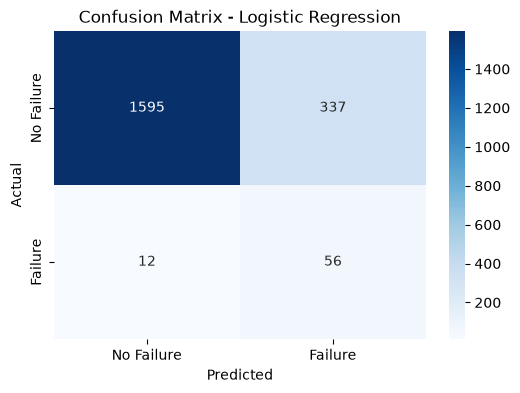

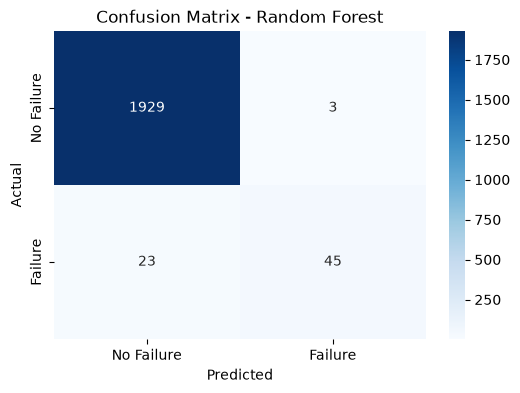

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [6]:
import pandas as pd

df = pd.read_csv("../data/processed/ai4i_cleaned.csv")

print("Dataset loaded successfully!")
print(df.shape)
df.head()

Dataset loaded successfully!
(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
# Remove unnecessary columns
columns_to_drop = [
    "UDI", "Product ID",
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

df = df.drop(columns=columns_to_drop, errors="ignore")

# Feature engineering
df["Temperature Difference [K]"] = (
    df["Process temperature [K]"] -
    df["Air temperature [K]"]
)

print("Feature preparation completed!")

Feature preparation completed!


In [8]:
X = df.drop(columns=["Machine failure"])
y = df["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 7)
Target shape: (10000,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 7)
Testing data: (2000, 7)


In [15]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training:", X_fit.shape)
print("Validation:", X_val.shape)

Model training: (6400, 7)
Validation: (1600, 7)


phase 5

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample"
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_fit, y_fit)

print("Best Parameters:")
print(random_search.best_params_)

print("Best Cross-validation PR-AUC:")
print(random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 30}
Best Cross-validation PR-AUC:
0.8062939625336728


In [17]:
import numpy as np
from sklearn.metrics import precision_recall_curve

best_model = random_search.best_estimator_

val_probabilities = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Example target: recall of at least 80%
target_recall = 0.80

valid_indices = np.where(recall[:-1] >= target_recall)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(precision[:-1][valid_indices])
    ]
    best_threshold = thresholds[best_index]
else:
    raise ValueError(
        "No threshold achieved the selected recall target. "
        "Review the target recall or model."
    )

print("Selected threshold:", best_threshold)
print("Validation precision:", precision[best_index])
print("Validation recall:", recall[best_index])

Selected threshold: 0.15390559145689522
Validation precision: 0.4489795918367347
Validation recall: 0.8148148148148148


In [18]:
best_model.fit(X_train, y_train)

test_probabilities = best_model.predict_proba(X_test)[:, 1]

y_pred_final = (
    test_probabilities >= best_threshold
).astype(int)

In [19]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

print("Final Classification Report:")
print(classification_report(y_test, y_pred_final))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("PR-AUC:", average_precision_score(
    y_test, test_probabilities
))

print("ROC-AUC:", roc_auc_score(
    y_test, test_probabilities
))

Final Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      1932
           1       0.49      0.88      0.63        68

    accuracy                           0.96      2000
   macro avg       0.74      0.92      0.80      2000
weighted avg       0.98      0.96      0.97      2000

Confusion Matrix:
[[1869   63]
 [   8   60]]
PR-AUC: 0.858536015396839
ROC-AUC: 0.9731191389599319


In [20]:
uv add joblib

Note: you may need to restart the kernel to use updated packages.


d:\FactoryMindAI\.venv\Scripts\python.exe: No module named uv


In [21]:
import joblib
from pathlib import Path

model_directory = Path("../models")
model_directory.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "pipeline": best_model,
    "threshold": float(best_threshold),
    "features": list(X_train.columns)
}

joblib.dump(
    model_artifact,
    model_directory / "factorymind_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [22]:
loaded_artifact = joblib.load(
    model_directory / "factorymind_model.pkl"
)

loaded_model = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

sample = X_test.iloc[[0]]

probability = loaded_model.predict_proba(sample)[0][1]

prediction = int(probability >= loaded_threshold)

print("Failure probability:", probability)
print("Predicted failure:", prediction)

Failure probability: 0.1653616333986387
Predicted failure: 1
